<a href="https://colab.research.google.com/github/nizarbanu/BPN/blob/main/Backpropagation_Neural_Network_Learner_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Backpropagation in a Neural Network

**Purpose:** Understand how a feedforward neural network makes a prediction, measures its error, sends gradients backward, and updates its weights to learn.

**Tools:** Python, NumPy, Matplotlib  
**Prerequisites:** Basic Python, multiplication/addition, and the idea of a derivative.

## 1. Learning objectives

By the end of this notebook, you should be able to:

- Identify the input, hidden, and output layers of a neural network.
- Explain the forward pass and calculate a neuron’s weighted sum and activation.
- Calculate a loss that measures the difference between prediction and target.
- Explain how the chain rule helps backpropagation calculate gradients.
- Update weights and biases using gradient descent.
- Implement a small neural network using NumPy and observe it learning the XOR pattern.

## 2. Why do we need backpropagation?

A neural network begins with weights that usually do not produce accurate predictions. During training, it compares its prediction with the expected answer. Backpropagation calculates how each weight and bias contributed to the loss. Gradient descent then uses these gradients to update the parameters.

**Remember the distinction:**
- **Forward propagation** computes a prediction.
- **Loss calculation** measures prediction error.
- **Backpropagation** calculates gradients of the loss.
- **Gradient descent** uses those gradients to update weights and biases.

## 3. Understand the network architecture

The example below is a fully connected feedforward neural network. Each input is connected to each neuron in the hidden layer, and each hidden neuron is connected to the output neuron.

- **Inputs:** the features supplied to the network.
- **Weights:** control the influence of one neuron on another.
- **Biases:** adjustable values added to weighted sums.
- **Hidden layer:** learns intermediate patterns.
- **Output:** the network’s prediction.

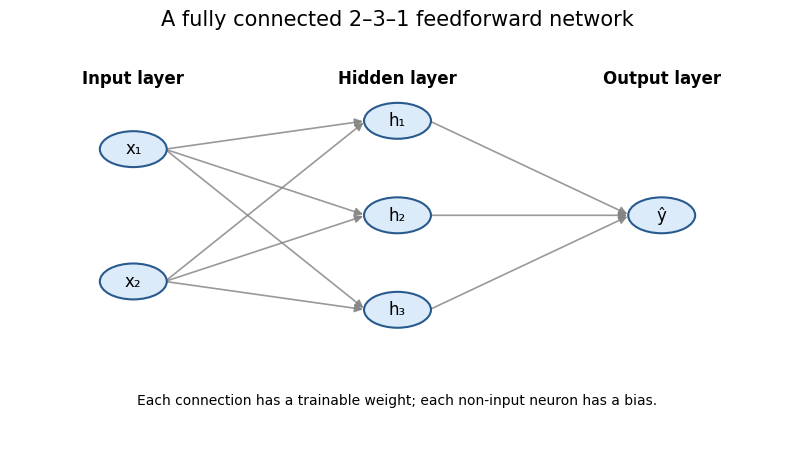

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.set_xlim(-0.7, 3.7)
ax.set_ylim(-0.7, 3.7)
ax.axis("off")

layers = {
    "Input layer": [(0, 2.6, "x₁"), (0, 1.2, "x₂")],
    "Hidden layer": [(1.5, 2.9, "h₁"), (1.5, 1.9, "h₂"), (1.5, 0.9, "h₃")],
    "Output layer": [(3, 1.9, "ŷ")]
}
# Connections first
for x0, y0, _ in layers["Input layer"]:
    for x1, y1, _ in layers["Hidden layer"]:
        ax.add_patch(FancyArrowPatch((x0+0.18, y0), (x1-0.18, y1),
                                     arrowstyle="-|>", mutation_scale=12,
                                     linewidth=1.2, color="gray", alpha=0.8))
for x0, y0, _ in layers["Hidden layer"]:
    x1, y1, _ = layers["Output layer"][0]
    ax.add_patch(FancyArrowPatch((x0+0.18, y0), (x1-0.18, y1),
                                 arrowstyle="-|>", mutation_scale=12,
                                 linewidth=1.2, color="gray", alpha=0.8))
for name, nodes in layers.items():
    for x, y, label in nodes:
        circ = Circle((x, y), 0.19, facecolor="#DCEBFA", edgecolor="#285A8E", linewidth=1.5)
        ax.add_patch(circ)
        ax.text(x, y, label, ha="center", va="center", fontsize=12)
    xmid = nodes[0][0]
    ax.text(xmid, 3.35, name, ha="center", va="center", fontsize=12, weight="bold")
ax.text(1.5, -0.1, "Each connection has a trainable weight; each non-input neuron has a bias.",
        ha="center", fontsize=10)
ax.set_title("A fully connected 2–3–1 feedforward network", fontsize=15, pad=14)
plt.show()

## 4. What happens inside one neuron?

A neuron first calculates a weighted sum and adds a bias:

$$
z = w_1x_1 + w_2x_2 + b
$$

It then applies an activation function. We use the sigmoid function for the worked example:
$$
sigma(z)=\frac{1}{1+e^{-z}}
$$

The sigmoid maps any real input to a value between zero and one. Its derivative can be written in terms of its output:

$$
sigma'(z)=\sigma(z)(1-\sigma(z))
$$

**Remember:** weighted sum first, activation second.

## 5. The training cycle

A neural network learns by repeating these steps over training examples.

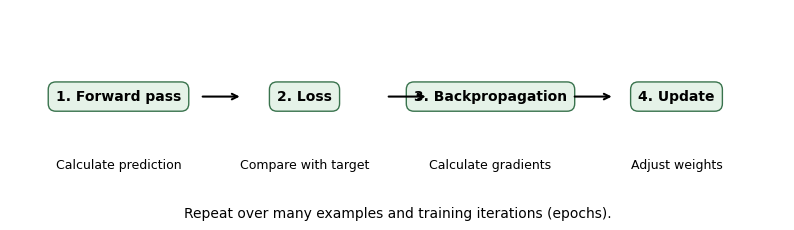

In [ ]:
fig, ax = plt.subplots(figsize=(10, 2.7))
ax.axis("off")
steps = [
    (0.05, "1. Forward pass", "Calculate prediction"),
    (0.29, "2. Loss", "Compare with target"),
    (0.53, "3. Backpropagation", "Calculate gradients"),
    (0.77, "4. Update", "Adjust weights")
]
for x, title, subtitle in steps:
    ax.text(x+0.09, 0.58, title, ha="center", va="center", fontsize=10, weight="bold",
            bbox=dict(boxstyle="round,pad=0.55", facecolor="#E5F2E8", edgecolor="#39734D"),
            transform=ax.transAxes)
    ax.text(x+0.09, 0.25, subtitle, ha="center", va="center", fontsize=9, transform=ax.transAxes)
for x in [0.19, 0.43, 0.67]:
    ax.annotate("", xy=(x+0.110, 0.58), xytext=(x+0.055, 0.58),
                xycoords=ax.transAxes, arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.5, 0.02, "Repeat over many examples and training iterations (epochs).",
        ha="center", va="center", fontsize=10, transform=ax.transAxes)
plt.show()

## 6. Loss: how wrong was the prediction?

For a simple numerical example, we will use **squared error** for one output:

$$
L=\frac{1}{2}(\hat{y}-y)^2
$$

where:

- y is the target (expected output),
- \$\hat{y}$ is the predicted output,
- L is the loss.

The factor one-half makes the derivative convenient.

It does not change which prediction minimizes the loss.

For this example, the output neuron uses sigmoid activation. We will calculate gradients using the chain rule.

## 7. Worked numerical example: one training step

Consider a small network with two inputs, two hidden neurons and one output. The weights and biases are fixed below. We will calculate the prediction, loss, gradients, and updated parameters for **one** training example.

Input: \(x_1=1.0, x_2=0.5\)  
Target: $y = 1.0$
Learning rate: $\eta = 0.1$

The hidden and output neurons use sigmoid activation.

In [ ]:
import numpy as np

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# One input example, shape (2,)
x = np.array([1.0, 0.5])
target = 1.0
learning_rate = 0.1

# Weights from input to hidden: rows = input features, columns = hidden neurons
W1 = np.array([[0.10, -0.20],
               [0.40,  0.20]])
b1 = np.array([0.0, 0.1])

# Weights from hidden to output
W2 = np.array([0.30, -0.10])
b2 = 0.05

# Forward pass
z1 = x @ W1 + b1
h = sigmoid(z1)
z2 = h @ W2 + b2
prediction = sigmoid(z2)
loss = 0.5 * (prediction - target) ** 2

print("Hidden weighted sums z1:", np.round(z1, 4))
print("Hidden activations h:", np.round(h, 4))
print("Output weighted sum z2:", round(float(z2), 4))
print("Prediction:", round(float(prediction), 4))
print("Target:", target)
print("Loss:", round(float(loss), 6))

Hidden weighted sums z1: [0.3 0. ]
Hidden activations h: [0.5744 0.5   ]
Output weighted sum z2: 0.1723
Prediction: 0.543
Target: 1.0
Loss: 0.104435


### 7.1 Backpropagation at the output neuron

The loss depends on the prediction, and the prediction depends on the output weighted sum. Applying the chain rule gives:

$$ frac{\partial L}{\partial z_2}
= (\hat{y}-y)\,\hat{y}(1-\hat{y})
$$

This quantity tells us how the loss changes when the output weighted sum changes.

For the output weights:

$$
frac{\partial L}{\partial w^{(2)}_j}
= h_j\frac{\partial L}{\partial z_2}
$$
For the output bias:

$$
\frac{\partial L}{\partial b_2}
=\frac{\partial L}{\partial z_2}
$$

In [ ]:
# Backward pass: output layer
delta_out = (prediction - target) * prediction * (1.0 - prediction)

grad_W2 = h * delta_out
grad_b2 = delta_out

# Backpropagate to hidden layer
# Use the current (pre-update) output weights to calculate hidden gradients.
delta_hidden = (W2 * delta_out) * h * (1.0 - h)
grad_W1 = np.outer(x, delta_hidden)
grad_b1 = delta_hidden

print("Output delta:", round(float(delta_out), 6))
print("Gradient for W2:", np.round(grad_W2, 6))
print("Gradient for b2:", round(float(grad_b2), 6))
print("Hidden-layer deltas:", np.round(delta_hidden, 6))
print("Gradient for W1:\n", np.round(grad_W1, 6))
print("Gradient for b1:", np.round(grad_b1, 6))

Output delta: -0.113412
Gradient for W2: [-0.065148 -0.056706]
Gradient for b2: -0.113412
Hidden-layer deltas: [-0.008317  0.002835]
Gradient for W1:
 [[-0.008317  0.002835]
 [-0.004159  0.001418]]
Gradient for b1: [-0.008317  0.002835]


### 7.2 Update the weights and biases

Gradient descent moves each parameter in the direction that reduces the loss:

$$
w_{new}=w_{old}-\eta\frac{\partial L}{\partial w}
 $$

The same rule applies to biases. Notice that the gradient is subtracted. The gradient points toward increasing loss, so moving in the opposite direction tends to reduce it.

In [ ]:
W1_new = W1 - learning_rate * grad_W1
b1_new = b1 - learning_rate * grad_b1
W2_new = W2 - learning_rate * grad_W2
b2_new = b2 - learning_rate * grad_b2

# Forward pass after the update
z1_new = x @ W1_new + b1_new
h_new = sigmoid(z1_new)
z2_new = h_new @ W2_new + b2_new
prediction_new = sigmoid(z2_new)
loss_new = 0.5 * (prediction_new - target) ** 2

print("Updated W1:\n", np.round(W1_new, 5))
print("Updated b1:", np.round(b1_new, 5))
print("Updated W2:", np.round(W2_new, 5))
print("Updated b2:", round(float(b2_new), 5))
print("\nPrediction before update:", round(float(prediction), 6))
print("Prediction after update: ", round(float(prediction_new), 6))
print("Loss before update:", round(float(loss), 6))
print("Loss after update: ", round(float(loss_new), 6))

Updated W1:
 [[ 0.10083 -0.20028]
 [ 0.40042  0.19986]]
Updated b1: [0.00083 0.09972]
Updated W2: [ 0.30651 -0.09433]
Updated b2: 0.06134

Prediction before update: 0.542977
Prediction after update:  0.547458
Loss before update: 0.104435
Loss after update:  0.102397


**Interpret the result:** For this chosen example, check whether the loss decreased after the update. One update does not guarantee that loss decreases for every possible learning rate or example, but a suitably small gradient-descent step generally reduces the loss locally.

## 8. Visualize the backward direction

During the forward pass, activations move from inputs toward the output. During backpropagation, gradients are calculated starting at the loss and move backward through the network using the chain rule. The network is not sending the prediction backward; it is calculating how parameters affect the loss.

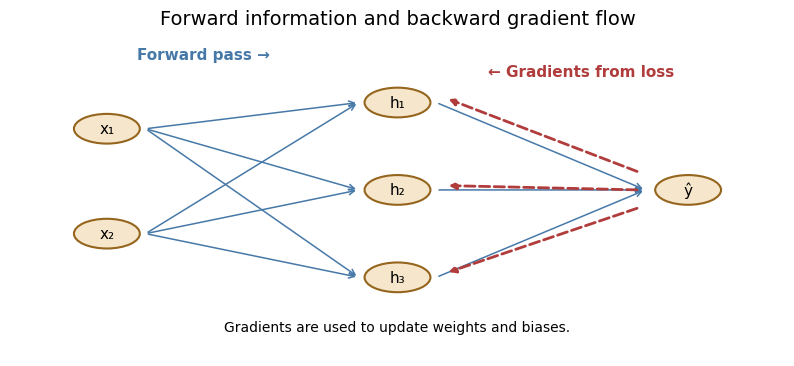

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-0.4, 3.3)
ax.axis("off")

input_nodes = [(0, 2.2, "x₁"), (0, 1.0, "x₂")]
hidden_nodes = [(1.5, 2.5, "h₁"), (1.5, 1.5, "h₂"), (1.5, 0.5, "h₃")]
output_nodes = [(3, 1.5, "ŷ")]

for group in [input_nodes, hidden_nodes, output_nodes]:
    for xx, yy, label in group:
        circ = plt.Circle((xx, yy), 0.17, facecolor="#F5E6CC", edgecolor="#95651D", lw=1.5)
        ax.add_patch(circ)
        ax.text(xx, yy, label, ha="center", va="center", fontsize=11)

# Forward arrows
for x0, y0, _ in input_nodes:
    for x1, y1, _ in hidden_nodes:
        ax.annotate("", xy=(x1-0.2, y1), xytext=(x0+0.2, y0),
                    arrowprops=dict(arrowstyle="->", color="#4779A8", lw=1.1))
for x0, y0, _ in hidden_nodes:
    ax.annotate("", xy=(2.78, 1.5), xytext=(x0+0.2, y0),
                arrowprops=dict(arrowstyle="->", color="#4779A8", lw=1.1))

# Backward gradient arrows
ax.annotate("", xy=(1.75, 2.55), xytext=(2.75, 1.7),
            arrowprops=dict(arrowstyle="-|>", color="#B13C3C", lw=2, linestyle="--"))
ax.annotate("", xy=(1.75, 1.55), xytext=(2.75, 1.5),
            arrowprops=dict(arrowstyle="-|>", color="#B13C3C", lw=2, linestyle="--"))
ax.annotate("", xy=(1.75, 0.55), xytext=(2.75, 1.3),
            arrowprops=dict(arrowstyle="-|>", color="#B13C3C", lw=2, linestyle="--"))
ax.text(0.5, 3.0, "Forward pass →", color="#4779A8", fontsize=11, weight="bold", ha="center")
ax.text(2.45, 2.8, "← Gradients from loss", color="#B13C3C", fontsize=11, weight="bold", ha="center")
ax.text(1.5, -0.12, "Gradients are used to update weights and biases.", ha="center", fontsize=10)
ax.set_title("Forward information and backward gradient flow", fontsize=14)
plt.show()

## 9. Implement backpropagation from scratch: the XOR problem

The XOR truth table is a classic beginner example because a single linear neuron cannot represent it. A network with a hidden layer can learn the pattern.

| Input 1 | Input 2 | Target |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

We will use a network with **2 input features, 4 hidden neurons and 1 output neuron**. This implementation uses NumPy for the forward pass, backpropagation, and gradient-descent updates—without an automatic-differentiation framework.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

# XOR training data
X = np.array([[0., 0.],
              [0., 1.],
              [1., 0.],
              [1., 1.]])
y = np.array([[0.],
              [1.],
              [1.],
              [0.]])

def sigmoid(z):
    # Clipping keeps exp() numerically stable for this small example.
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Parameters: 2 inputs -> 4 hidden units -> 1 output
W1 = np.random.randn(2, 4) * 0.8
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * 0.8
b2 = np.zeros((1, 1))

learning_rate = 1.0
epochs = 12000
loss_history = []

for epoch in range(epochs):
    # Forward pass
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)
    z2 = a1 @ W2 + b2
    y_hat = sigmoid(z2)

    # Mean squared error loss
    loss = np.mean((y_hat - y) ** 2)
    loss_history.append(loss)

    # Backpropagation: derivative of mean squared error
    # dL/dy_hat = 2*(y_hat-y)/number_of_elements
    d_yhat = 2 * (y_hat - y) / y.size
    delta2 = d_yhat * y_hat * (1 - y_hat)

    dW2 = a1.T @ delta2
    db2 = np.sum(delta2, axis=0, keepdims=True)

    delta1 = (delta2 @ W2.T) * a1 * (1 - a1)
    dW1 = X.T @ delta1
    db1 = np.sum(delta1, axis=0, keepdims=True)

    # Gradient-descent update
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

print("Final loss:", round(float(loss_history[-1]), 6))

Final loss: 0.000162


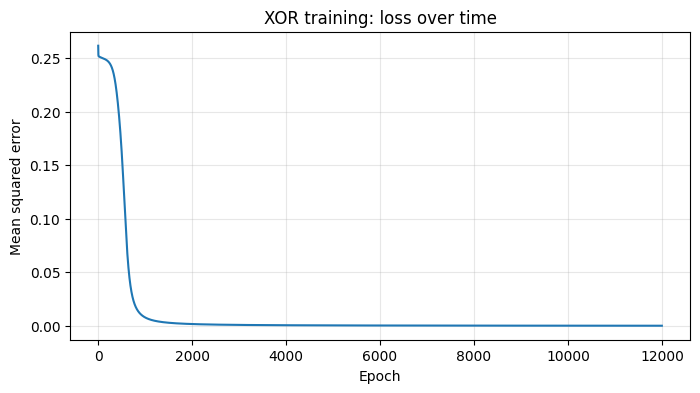

Input -> Target -> Prediction
[0 0] -> 0 -> 0.0136
[0 1] -> 1 -> 0.9885
[1 0] -> 1 -> 0.9860
[1 1] -> 0 -> 0.0115


In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("XOR training: loss over time")
plt.grid(True, alpha=0.3)
plt.show()

# Final predictions
a1 = sigmoid(X @ W1 + b1)
predictions = sigmoid(a1 @ W2 + b2)

print("Input -> Target -> Prediction")
for xi, target_i, pred_i in zip(X, y, predictions):
    print(f"{xi.astype(int)} -> {int(target_i[0])} -> {pred_i[0]:.4f}")

### 9.1 Interpret the results

- The loss should generally decrease as training progresses.
- Predictions for inputs with target 1 should move closer to 1.
- Predictions for inputs with target 0 should move closer to 0.
- Exact results can vary if you change the random seed, hidden-unit count, learning rate, or number of epochs.

For this small example, we use sigmoid activation and mean squared error for transparency. Binary cross-entropy is also commonly used for binary classification.

## 10. Explore and experiment

Try one change at a time and record what happens.

1. Change the hidden layer from 4 neurons to 2, then 8. Does the network still learn XOR?
2. Reduce the learning rate from 1.0 to 0.1. How does the loss curve change?
3. Increase the number of epochs to 20,000. Does the final loss improve?
4. Change the random seed. Do you get exactly the same predictions?
5. Temporarily remove the hidden layer in a separate implementation. Why is XOR difficult for a single linear decision boundary?

**Record:** the setting you changed, the final loss, the four predictions, and your interpretation.

## 11. Answer these questions

1. What is the difference between a weight and a bias?
2. What is calculated during the forward pass?
3. Why do we calculate a loss?
4. What does backpropagation calculate?
5. What role does the chain rule play?
6. Why do we subtract the gradient during gradient descent?
7. Why does XOR need a hidden layer for a standard feedforward network?
8. Does backpropagation itself update weights, or does the optimizer use the gradients to update them?

### Activity

For a neuron with input \(x=0.8\), weight \(w=0.5\), and bias \(b=-0.1\):

- Calculate \(z=wx+b\).
- Calculate the sigmoid activation.
- Explain what would change if the weight increased slightly.

## 12. Summary:

- A neural network produces predictions through forward propagation.
- A loss function measures the difference between predictions and targets.
- Backpropagation uses the chain rule to calculate gradients for weights and biases.
- Gradient descent updates parameters in the direction intended to reduce the loss.
- Training repeats forward pass → loss → backward pass → parameter update.
- Backpropagation is used to train many neural network architectures, including feedforward networks, CNNs, and RNNs (with backpropagation through time for recurrent connections).

## Further reading

- GeeksforGeeks, *Backpropagation in Neural Network*: https://www.geeksforgeeks.org/machine-learning/backpropagation-in-neural-network/
- University of Toronto, CSC311, *The Backpropagation Algorithm*: https://www.teach.cs.toronto.edu/~csc311notes/neural_networks/backpropagation.html
- Goodfellow, Bengio and Courville, *Deep Learning*, Chapter 6 (Deep Feedforward Networks): https://www.deeplearningbook.org/
